# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
import matplotlib.pyplot as plt


class Heap:
    """Min heap con las mismas convenciones de
    https://www.cs.usfca.edu/~galles/visualization/Heap.html

    - self.arreglo[0] es -INF y no hace parte del heap.
    - La raíz está en self.arreglo[1].
    - Los hijos de la posición i están en 2*i y 2*i + 1.
    """

    def __init__(self):
        self.arreglo = [float('-inf')]

    # ------------------------------------------------------------------
    # Auxiliares
    # ------------------------------------------------------------------
    def __len__(self):
        return len(self.arreglo) - 1

    def _intercambiar(self, i, j):
        self.arreglo[i], self.arreglo[j] = self.arreglo[j], self.arreglo[i]

    def _subir(self, i):
        """Sube el elemento en i mientras sea menor que su padre."""
        while i > 1 and self.arreglo[i] < self.arreglo[i // 2]:
            self._intercambiar(i, i // 2)
            i = i // 2

    def _bajar(self, i):
        """Baja el elemento en i mientras algún hijo sea menor que él.
        Si los dos hijos son iguales se elige el izquierdo (como la página)."""
        n = len(self)
        while 2 * i <= n:
            menor = 2 * i
            if 2 * i + 1 <= n and self.arreglo[2 * i + 1] < self.arreglo[2 * i]:
                menor = 2 * i + 1
            if self.arreglo[menor] < self.arreglo[i]:
                self._intercambiar(i, menor)
                i = menor
            else:
                break

    # ------------------------------------------------------------------
    # Operaciones de la página
    # ------------------------------------------------------------------
    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        self._subir(len(self))
        if imagen:
            self.dibujar(f"insert({valor})")

    def remove_smallest(self, imagen=False):
        if len(self) == 0:
            if imagen:
                self.dibujar("remove_smallest() — heap vacío")
            return None
        menor = self.arreglo[1]
        ultimo = self.arreglo.pop()
        if len(self) > 0:
            self.arreglo[1] = ultimo
            self._bajar(1)
        if imagen:
            self.dibujar(f"remove_smallest() → {menor}")
        return menor

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        for i in range(len(self) // 2, 0, -1):
            self._bajar(i)
        if imagen:
            self.dibujar("build_heap")

    # ------------------------------------------------------------------
    # Imagen
    # ------------------------------------------------------------------
    def dibujar(self, titulo=""):
        """Muestra el árbol del heap (sin el -INF de la posición 0)."""
        n = len(self)
        if n == 0:
            fig, ax = plt.subplots(figsize=(4, 1.5))
            ax.text(0.5, 0.5, "Heap vacío", ha="center", va="center", fontsize=12)
            ax.set_title(titulo)
            ax.axis("off")
            plt.show()
            return

        niveles = n.bit_length()          # profundidad del árbol completo
        ancho_hojas = 2 ** (niveles - 1)  # nodos posibles en el último nivel

        # Posición de cada nodo: cada nivel parte el ancho en partes iguales,
        # así el hijo izquierdo queda a la izquierda y el derecho a la derecha.
        pos = {}
        for i in range(1, n + 1):
            nivel = i.bit_length() - 1
            k = i - 2 ** nivel                # índice dentro del nivel
            x = (k + 0.5) / 2 ** nivel * ancho_hojas
            y = -nivel
            pos[i] = (x, y)

        fig, ax = plt.subplots(figsize=(max(4, 0.9 * ancho_hojas + 1), 1.2 * niveles + 0.8))

        # Aristas
        for i in range(1, n + 1):
            for hijo in (2 * i, 2 * i + 1):
                if hijo <= n:
                    (x1, y1), (x2, y2) = pos[i], pos[hijo]
                    ax.plot([x1, x2], [y1, y2], color="black", linewidth=1, zorder=1)

        # Nodos
        for i in range(1, n + 1):
            x, y = pos[i]
            ax.add_patch(plt.Circle((x, y), 0.3, facecolor="#cfe8ff",
                                    edgecolor="black", zorder=2))
            ax.text(x, y, str(self.arreglo[i]), ha="center", va="center",
                    fontsize=10, zorder=3)

        ax.set_xlim(-0.5, ancho_hojas + 0.5)
        ax.set_ylim(-niveles + 0.4, 0.6)
        ax.set_aspect("equal")
        ax.axis("off")
        if titulo:
            ax.set_title(titulo)
        plt.show()


if __name__ == "__main__":
    H = Heap()
    H.insert(10)
    H.insert(4)
    H.insert(7)
    print(H.arreglo)          # [-inf, 4, 10, 7]
    H.remove_smallest()
    print(H.arreglo)          # [-inf, 7, 10]
    H.build_heap(range(31, 0, -1))
    print(H.arreglo)

Writing heap.py


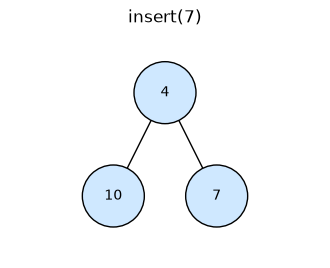

In [2]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)